<a href="https://colab.research.google.com/github/amanpoonia/SBeta_preparation/blob/main/Backtesting/WF_fundamentals.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
'''
AIM: Understand walkforward framework Test settings &
Performance metrics for backtesting

Backtest a strategy(MA crossover : Long when when price closes above the moving average and short when it falls below)

'''

# THING TO REMEMBER
'''
I kept using ^GSPC everywhere and now cannot just change asset at the top and rerun the code
Next time ^GSPC should be replaced by close or today
'''

/tmp/ipykernel_606/3599741292.py:9: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download('^GSPC', start=start_date, end=end_date)
[*********************100%***********************]  1 of 1 completed


Price             Close         High          Low         Open      Volume
Ticker            ^GSPC        ^GSPC        ^GSPC        ^GSPC       ^GSPC
Date                                                                      
2020-01-02  3257.850098  3258.139893  3235.530029  3244.669922  3459930000
2020-01-03  3234.850098  3246.149902  3222.340088  3226.360107  3484700000
2020-01-06  3246.280029  3246.840088  3214.639893  3217.550049  3702460000
2020-01-07  3237.179932  3244.909912  3232.429932  3241.860107  3435910000
2020-01-08  3253.050049  3267.070068  3236.669922  3238.590088  3726840000


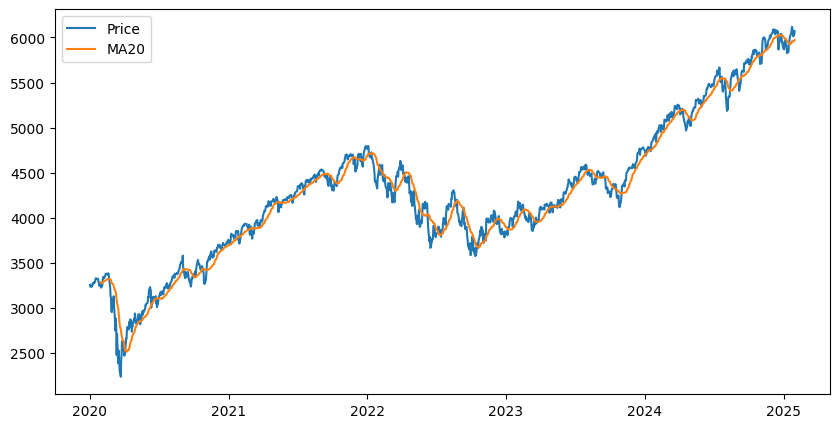

Ticker            ^GSPC         MA20  buy/sell
Date                                          
2020-01-02  3257.850098          NaN       NaN
2020-01-03  3234.850098          NaN       NaN
2020-01-06  3246.280029          NaN       NaN
2020-01-07  3237.179932          NaN       NaN
2020-01-08  3253.050049          NaN       NaN
2020-01-09  3274.699951          NaN       NaN
2020-01-10  3265.350098          NaN       NaN
2020-01-13  3288.129883          NaN       NaN
2020-01-14  3283.149902          NaN       NaN
2020-01-15  3289.290039          NaN       NaN
2020-01-16  3316.810059          NaN       NaN
2020-01-17  3329.620117          NaN       NaN
2020-01-21  3320.790039          NaN       NaN
2020-01-22  3321.750000          NaN       NaN
2020-01-23  3325.540039          NaN       NaN
2020-01-24  3295.469971          NaN       NaN
2020-01-27  3243.629883          NaN       NaN
2020-01-28  3276.239990          NaN       NaN
2020-01-29  3273.399902          NaN       NaN
2020-01-30  3

In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

start_date = '2020-01-01'
end_date = '2025-01-31'

data = yf.download('^GSPC', start=start_date, end=end_date)
print(data.head())

#rolling average of the last 20 days
price = data['Close'].copy()

price['MA20'] = price['^GSPC'].rolling(20).mean()

#plotting MA with prices
plt.figure(figsize=(10, 5))
plt.plot(price['^GSPC'], label='Price')
plt.plot(price['MA20'], label='MA20')
plt.legend()
plt.show()


#trading, trades at crossover
price['buy/sell'] = np.where(price['^GSPC'] > price['MA20'], 1, -1).astype(float)
#price['sell'] = np.where(price['^GSPC'] < price['MA20'], 1, 0)
price.loc[price['MA20'].isna(), 'buy/sell'] = np.nan


print(price.head(21))

Ticker            ^GSPC         MA20  buy/sell  pos   prev_close       ret  \
Date                                                                         
2020-01-31  3225.520020  3279.220496      -1.0  1.0  3283.659912 -0.017864   
2020-02-03  3248.919922  3279.923987      -1.0 -1.0  3225.520020  0.007228   
2020-02-04  3297.590088  3282.489490       1.0 -1.0  3248.919922  0.014869   
2020-02-05  3334.689941  3287.364990       1.0  1.0  3297.590088  0.011188   
2020-02-06  3345.780029  3292.001489       1.0  1.0  3334.689941  0.003320   
2020-02-07  3327.709961  3294.651990       1.0  1.0  3345.780029 -0.005415   
2020-02-10  3352.090088  3298.988989       1.0  1.0  3327.709961  0.007300   
2020-02-11  3357.750000  3302.469995       1.0  1.0  3352.090088  0.001687   
2020-02-12  3379.449951  3307.284998       1.0  1.0  3357.750000  0.006442   
2020-02-13  3373.939941  3311.517493       1.0  1.0  3379.449951 -0.001632   

Ticker      ret_simple  ret_strat  cum_ret_strat  
Date        

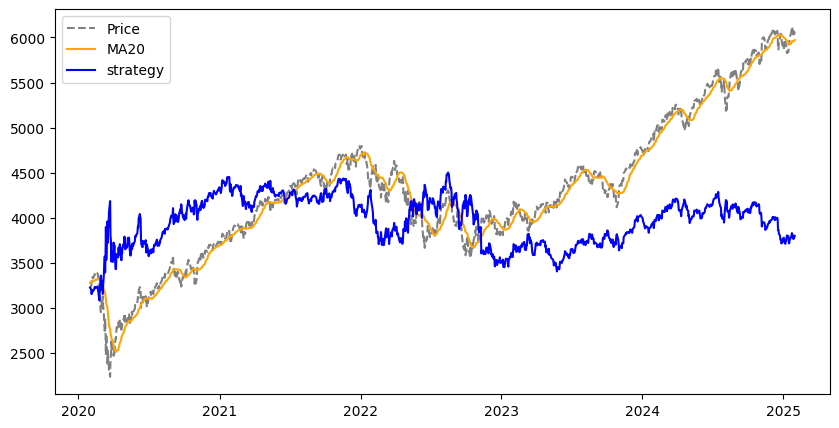

In [ ]:
'''
Correctly aligning signal and return data

Signal is generated on time t
Trade(buy/sell) on time t
Held from time t to t+1
return on this trade at t+1.

ret_trade(t+1) = signal(t) * [P(t+1)-P(t)]/P(t)
'''

# position held over the day t
price['pos'] = price['buy/sell'].shift(1)

# entry price
price['prev_close'] = price['^GSPC'].shift(1)

# return of holding it for a day
price['ret'] = np.log(price['^GSPC']/price['prev_close'])
price['ret_simple'] = price['^GSPC'].pct_change()

#return of the strategy
price['ret_strat'] = np.log1p(price['pos'] * price['ret_simple'])

price.dropna(inplace=True)

# portfolio value
price['cum_ret_strat'] = price['prev_close'].iloc[0] * np.exp(price['ret_strat'].cumsum())
print(price.head(10))

plt.figure(figsize=(10, 5))
plt.plot(price['^GSPC'], label='Price', color = 'gray', linestyle = '--')
plt.plot(price['MA20'], label='MA20', color = 'orange')
plt.plot(price['cum_ret_strat'], label='strategy', color = 'blue')
plt.legend()
plt.show()

**OBSERVATION**

Seems like a fundamental issue with the strategy.

Possibly, the interaction days between MA and prices, the trade reversal days are the issue.
By the time we reverse the trade, damage is already done


In [ ]:
# metrics

price['pos_change'] = price['pos'] != price['pos'].shift(1)
price['trade_no'] = price['pos_change'].cumsum()
price['date'] = price.index

metrics = price.groupby('trade_no').agg(
    position = ('pos', 'first'),
    days_in_trade = ('trade_no', 'count'),
    ret_trade = ('ret_strat', 'sum'),
    entry_price = ('prev_close', 'first'),
    exit_price = ('^GSPC', 'last'),
    entry_date = ('date', 'first'),
    exit_date = ('date', 'last')
).reset_index(drop=True)

metrics['ret_simple_trade'] = np.expm1(metrics['ret_trade'])
metrics['fixed_ret'] = metrics['position'] * (metrics['exit_price'] / metrics['entry_price'] - 1)
metrics

,position,days_in_trade,ret_trade,entry_price,exit_price,entry_date,exit_date,ret_simple_trade,fixed_ret
0,1.0,1,-0.017864,3283.659912,3225.520020,2020-01-31,2020-01-31,-0.017706,-0.017706
1,-1.0,2,-0.022375,3225.520020,3297.590088,2020-02-03,2020-02-04,-0.022126,-0.022344
2,1.0,13,-0.021983,3297.590088,3225.889893,2020-02-05,2020-02-24,-0.021743,-0.021743
3,-1.0,30,0.107465,3225.889893,2663.679932,2020-02-25,2020-04-06,0.113452,0.174281
4,1.0,26,0.057028,2663.679932,2820.000000,2020-04-07,2020-05-13,0.058686,0.058686
...,...,...,...,...,...,...,...,...,...
114,1.0,29,-0.009640,5929.040039,5872.160156,2024-11-07,2024-12-18,-0.009593,-0.009593
115,-1.0,4,-0.028482,5872.160156,6040.040039,2024-12-19,2024-12-24,-0.028080,-0.028589
116,1.0,2,-0.011523,6040.040039,5970.839844,2024-12-26,2024-12-27,-0.011457,-0.011457
117,-1.0,11,0.002482,5970.839844,5949.910156,2024-12-30,2025-01-15,0.002485,0.003505


In [ ]:
# Performance
'''
See how long trades/short trades behaved
Their expected returns, average trading days, etc.
'''


long_trades = metrics[metrics['position'] == 1]
short_trades = metrics[metrics['position'] == -1]

print('PERFORMANCE METRICS')
print(f'Number of long trades: {len(long_trades)}')
print(f'Number of short trades: {len(short_trades)}')
print(f'avg length(days) in long trade: {long_trades['days_in_trade'].mean():.1f} days')
print(f'avg length(days) in short trade: {short_trades['days_in_trade'].mean():.1f} days')
print(f'ret from long: {long_trades['ret_trade'].sum():.4f}')
print(f'ret from short: {short_trades['ret_trade'].sum():.4f}')

PERFORMANCE METRICS
Number of long trades: 60
Number of short trades: 59
avg length(days) in long trade: 14.1 days
avg length(days) in short trade: 7.0 days
ret from long: 0.4574
ret from short: -0.3112


**OBSERVATION**

Somehow we have negative returns in our shorts, implying, if we held long only even in our predicated downdays, we would have outperformed this strategy.
i.e Buy and hold outperforms this MA20 strategy.

BELOW
NEXT COMPARE WITH SOME BENCHMARK OR BENCHMARK STRATEGY, like BUY AND HOLD

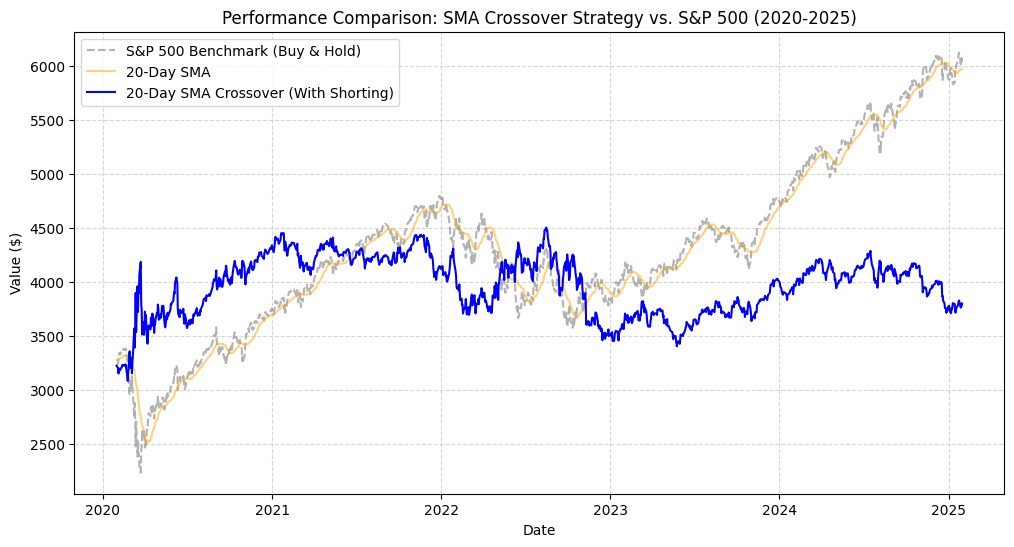

In [ ]:
#COMPARISION WITH BUY AND HOLD S&P

plt.figure(figsize=(12, 6))
# S&P 500 Benchmark (Buy & Hold from starting day)
plt.plot(price['^GSPC'], label='S&P 500 Benchmark (Buy & Hold)', color='gray', alpha=0.6, linestyle='--')
# 20-Day SMA Line
plt.plot(price['MA20'], label='20-Day SMA', color='orange', alpha=0.5)
# Cumulative Strategy Equity Curve (Starting at same initial index value)
plt.plot(price['cum_ret_strat'], label='20-Day SMA Crossover (With Shorting)', color='blue', linewidth=1.5)

plt.title('Performance Comparison: SMA Crossover Strategy vs. S&P 500 (2020-2025)')
plt.xlabel('Date')
plt.ylabel('Value ($)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
'''
WALK FORWARD FRAMEWORK BACKTESTING
'''
'''
Testing different MA durations in the train window. The best sharpe for that window is chosen and selected for
the testing in OOS(out of sample).
[Implementation requires a function that is called to do this]

Then rolling forward the training and testing window, while keeoing the start of training window anchored.
[a loop that uses the above function and tests.]
'''

In [2]:
# longer history, so we get enough folds
data  = yf.download('^GSPC', start='2005-01-01', end='2025-01-31')
close = data['Close']['^GSPC']

def backtest(close, window):
    """Daily strategy log returns for an MA(window) long/short rule."""
    ma     = close.rolling(window).mean()
    signal = pd.Series(np.where(close > ma, 1.0, -1.0), index=close.index)
    signal[ma.isna()] = np.nan              # no signal during warm-up
    pos    = signal.shift(1)                # decided at close t, held over t+1
    ret    = close.pct_change()
    return np.log1p(pos * ret)              # exact log returns, NaN in warm-up

def sharpe(log_ret):
    """Annualised Sharpe from daily log returns (risk-free = 0)."""
    r = np.expm1(log_ret.dropna())
    return np.sqrt(252) * r.mean() / r.std()

/tmp/ipykernel_606/2140492979.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data  = yf.download('^GSPC', start='2005-01-01', end='2025-01-31')
[*********************100%***********************]  1 of 1 completed


In [3]:
# Now the folds mechanism

train_window = 2  #years
test_window = 6 #months

folds = []

train_start = pd.to_datetime('2006-01-01')
end_date = pd.to_datetime('2025-01-30')

while True:
  test_start = train_start + pd.DateOffset(years=train_window)
  test_end = test_start + pd.DateOffset(months=test_window)

  if test_end > end_date:
    break;
  folds.append(
      {
          'train_start': train_start,
          'train_end': train_start + pd.DateOffset(years = train_window) - pd.DateOffset(days=1),
          'test_start': test_start,
          'test_end': test_end
      }
  )
  train_start += pd.DateOffset(months=test_window)


folds = pd.DataFrame(folds)

In [44]:
# trading days actually in each window
folds['n_train'] = [len(close.loc[a:b]) for a, b in zip(folds.train_start, folds.train_end)]
folds['n_test']  = [len(close.loc[a:b]) for a, b in zip(folds.test_start,  folds.test_end)]

print(len(folds), 'folds')
print(folds.head())
print(folds.tail())

34 folds
  train_start  train_end test_start   test_end  n_train  n_test
0  2006-01-01 2007-12-31 2008-01-01 2008-07-01      502     126
1  2006-07-01 2008-06-30 2008-07-01 2009-01-01      502     128
2  2007-01-01 2008-12-31 2009-01-01 2009-07-01      504     125
3  2007-07-01 2009-06-30 2009-07-01 2010-01-01      504     128
4  2008-01-01 2009-12-31 2010-01-01 2010-07-01      505     125
   train_start  train_end test_start   test_end  n_train  n_test
29  2020-07-01 2022-06-30 2022-07-01 2023-01-01      504     127
30  2021-01-01 2022-12-31 2023-01-01 2023-07-01      503     124
31  2021-07-01 2023-06-30 2023-07-01 2024-01-01      503     126
32  2022-01-01 2023-12-31 2024-01-01 2024-07-01      501     125
33  2022-07-01 2024-06-30 2024-07-01 2025-01-01      501     128


In [7]:
folds

,train_start,train_end,test_start,test_end,n_train
0,2006-01-01,2007-12-31,2008-01-01,2008-07-01,502
1,2006-07-01,2008-06-30,2008-07-01,2009-01-01,502
2,2007-01-01,2008-12-31,2009-01-01,2009-07-01,504
3,2007-07-01,2009-06-30,2009-07-01,2010-01-01,504
4,2008-01-01,2009-12-31,2010-01-01,2010-07-01,505
5,2008-07-01,2010-06-30,2010-07-01,2011-01-01,504
6,2009-01-01,2010-12-31,2011-01-01,2011-07-01,504
7,2009-07-01,2011-06-30,2011-07-01,2012-01-01,505
8,2010-01-01,2011-12-31,2012-01-01,2012-07-01,504
9,2010-07-01,2012-06-30,2012-07-01,2013-01-01,505


In [44]:
window = [10,20,200]

ret = pd.DataFrame({
    w: backtest(close, w) for w in window
})

is_sharpe = []

for i, f in folds.iterrows():
  train = ret.loc[f.train_start:f.train_end]
  is_sharpe.append(sharpe(train))

is_sharpe = pd.DataFrame(is_sharpe, index=folds.index)

folds['best_window'] = is_sharpe.idxmax(axis=1)
folds['is_sharpe'] = is_sharpe.max(axis=1)
folds['margin'] = is_sharpe.max(axis=1) - is_sharpe.median(axis=1)

print(folds[['train_start','train_end','best_window','best_sharpe','margin']])


   train_start  train_end  best_window  best_sharpe    margin
0   2006-01-01 2007-12-31          200    -0.545200  0.068327
1   2006-07-01 2008-06-30          200    -0.025115  0.558166
2   2007-01-01 2008-12-31          200     0.378129  1.056467
3   2007-07-01 2009-06-30          200     0.087211  0.535230
4   2008-01-01 2009-12-31          200     0.623903  0.950316
5   2008-07-01 2010-06-30          200     0.396733  0.420076
6   2009-01-01 2010-12-31           20     0.548118  0.601783
7   2009-07-01 2011-06-30           20     0.408726  0.027225
8   2010-01-01 2011-12-31           20    -0.262049  0.339257
9   2010-07-01 2012-06-30           20    -0.350289  0.219281
10  2011-01-01 2012-12-31          200    -0.391980  0.247691
11  2011-07-01 2013-06-30          200    -0.206491  0.383686
12  2012-01-01 2013-12-31          200     1.243404  1.013991
13  2012-07-01 2014-06-30          200     1.622900  2.082062
14  2013-01-01 2014-12-31          200     1.376308  1.626178
15  2013

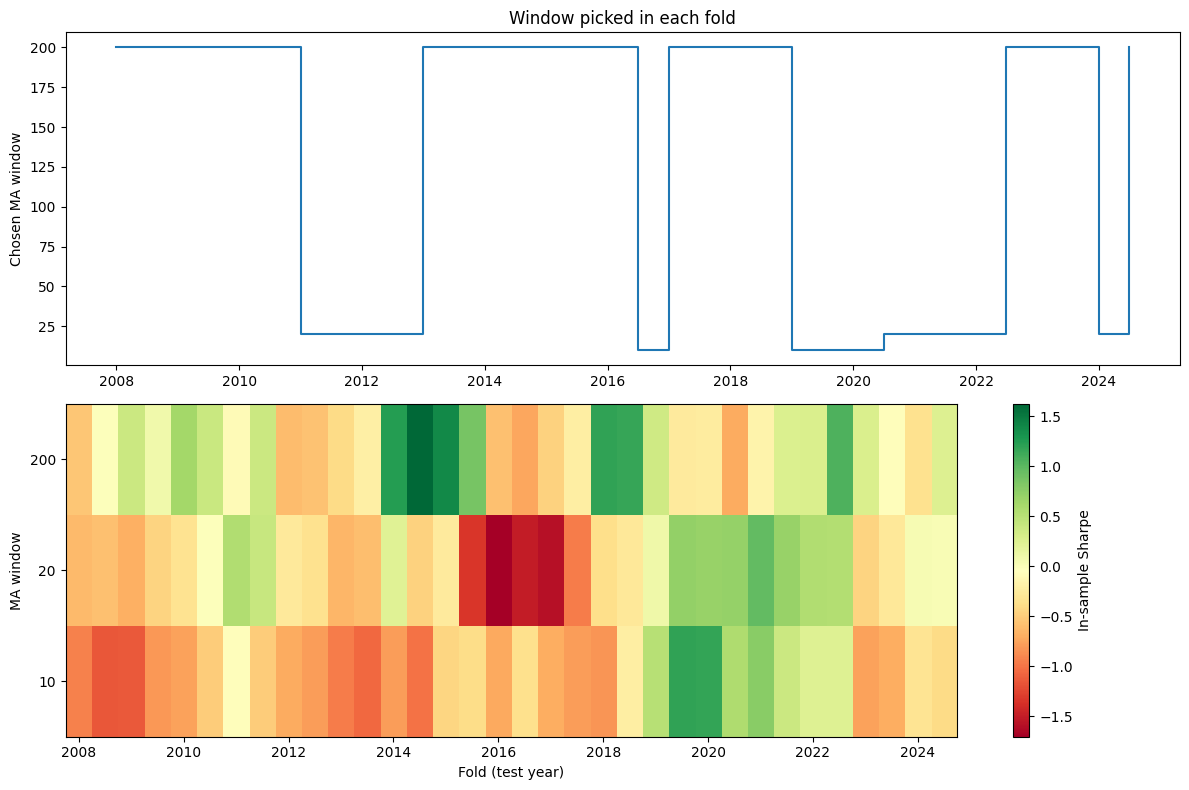

In [45]:
fig, ax = plt.subplots(2, 1, figsize=(12, 8))

# 1. chosen window over time
ax[0].step(folds.test_start, folds.best_window, where='post')
ax[0].set_ylabel('Chosen MA window')
ax[0].set_title('Window picked in each fold')

# 2. heatmap: in-sample Sharpe of every window in every fold
im = ax[1].imshow(is_sharpe.T.values, aspect='auto', origin='lower', cmap='RdYlGn')
ax[1].set_yticks(range(len(window)))
ax[1].set_yticklabels(window)
ax[1].set_xticks(range(0, len(folds), 4))
ax[1].set_xticklabels(folds.test_start.dt.year[::4])
ax[1].set_ylabel('MA window')
ax[1].set_xlabel('Fold (test year)')
plt.colorbar(im, ax=ax[1], label='In-sample Sharpe')
plt.tight_layout()
plt.show()

In [46]:
oos_pieces, window_pieces = [], []

for i , f in folds.iterrows():
  w = f.best_window
  r = ret.loc[f.test_start:f.test_end, w]
  oos_pieces.append(r)
  window_pieces.append(pd.Series(w, index=r.index))
  folds.loc[i, 'oos_sharpe'] = sharpe(r)

oos_ret = pd.concat(oos_pieces).rename('walk_forward')
oos_window = pd.concat(window_pieces).rename('live_window')

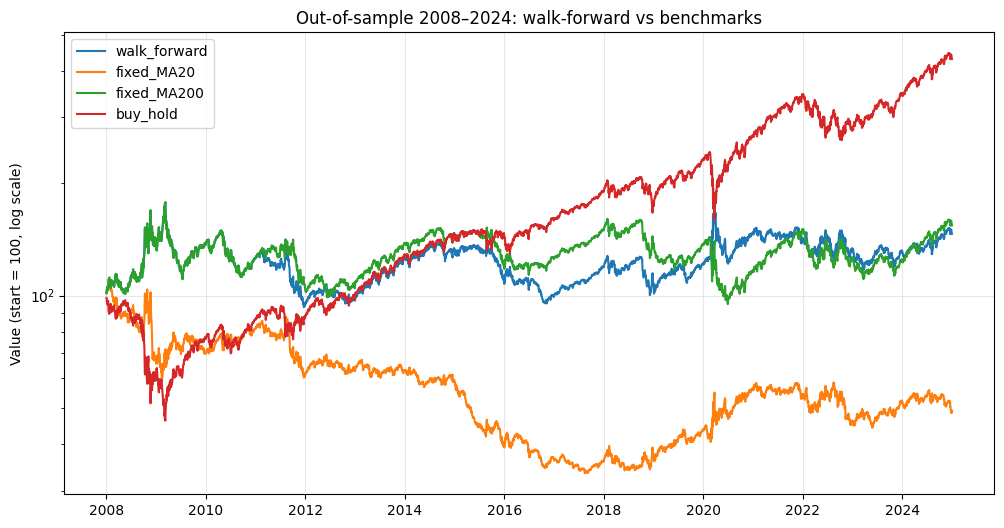

In [47]:
dates = oos_ret.index

bench = pd.DataFrame({
    'walk_forward': oos_ret,
    'fixed_MA20':   ret.loc[dates, 20],                              # your original rule
    'fixed_MA200':  ret.loc[dates, 200],                             # classic long-term rule
    'buy_hold':     np.log(close / close.shift(1)).loc[dates],            # S&P itself
})

equity = 100 * np.exp(bench.cumsum())

plt.figure(figsize=(12, 6))
for col in equity:
    plt.plot(equity[col], label=col)
plt.yscale('log')
plt.ylabel('Value (start = 100, log scale)')
plt.title('Out-of-sample 2008–2024: walk-forward vs benchmarks')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [65]:
def perf(log_r):
  r = np.expm1(log_r)
  years = len(log_r)/252
  eq = np.exp(log_r.cumsum())
  cagr = eq.iloc[-1] ** (1/years) - 1
  vol = r.std() * np.sqrt(252)
  sr = r.mean()/r.std() * np.sqrt(252)
  dd = eq/eq.cummax() - 1
  mdd = dd.min()

  calmar = cagr/abs(mdd)
  t_stat = sr * np.sqrt(years)

  return pd.Series(
      {
          'CAGR': cagr,
          'Vol': vol,
          'Sharpe': sr,
          'MaxDD': mdd,
          'Calmar': calmar,
          't_stat': t_stat
      }
  )
table = bench.apply(perf).T
print(table.round(3))

               CAGR    Vol  Sharpe  MaxDD  Calmar  t_stat
walk_forward  0.023  0.201   0.212 -0.477   0.047   0.874
fixed_MA20   -0.041  0.201  -0.106 -0.701  -0.058  -0.440
fixed_MA200   0.026  0.201   0.227 -0.467   0.055   0.938
buy_hold      0.089  0.201   0.527 -0.531   0.169   2.174


Mean in-sample Sharpe:   0.41
Out-of-sample Sharpe:    0.21
Walk-forward efficiency: 0.52
Rank corr IS vs OOS: -0.29


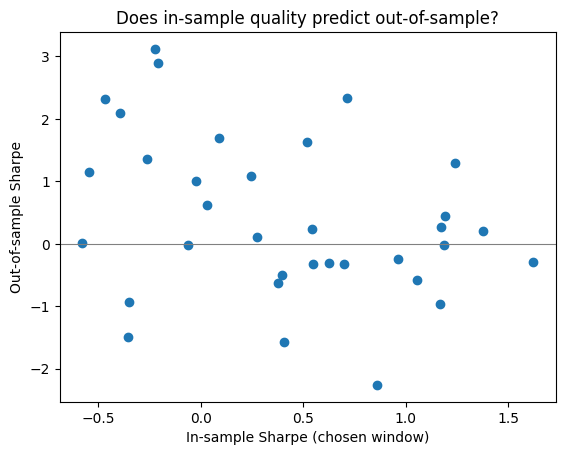

In [49]:
mean_is = folds['is_sharpe'].mean()
pooled_oos = sharpe(oos_ret)
wfe = pooled_oos / mean_is                      # walk-forward efficiency

print(f'Mean in-sample Sharpe:   {mean_is:.2f}')
print(f'Out-of-sample Sharpe:    {pooled_oos:.2f}')
print(f'Walk-forward efficiency: {wfe:.2f}')
print('Rank corr IS vs OOS:', folds[['is_sharpe', 'oos_sharpe']].corr(method='spearman').iloc[0, 1].round(2))

plt.scatter(folds.is_sharpe, folds.oos_sharpe)
plt.axhline(0, color='gray', lw=0.8)
plt.xlabel('In-sample Sharpe (chosen window)')
plt.ylabel('Out-of-sample Sharpe')
plt.title('Does in-sample quality predict out-of-sample?')
plt.show()

Walk-forward beats 67% of the 20 fixed windows


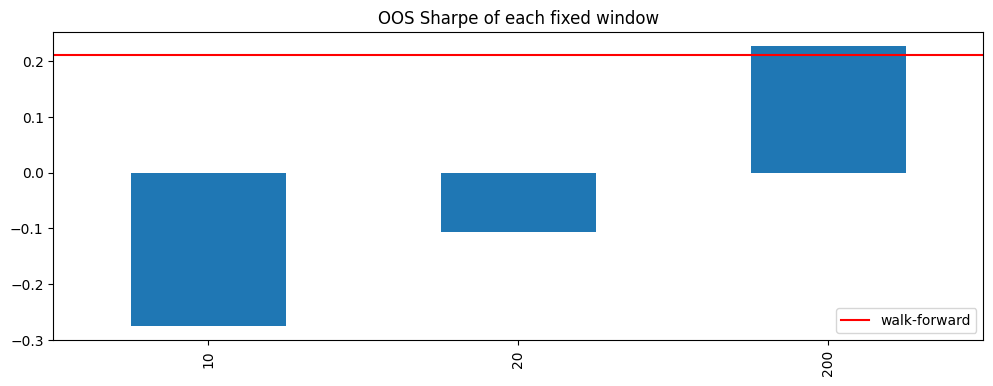

In [55]:
fixed_oos = ret.loc[dates].apply(sharpe)          # every fixed window over the same OOS dates
rank = (fixed_oos < pooled_oos).mean()

print(f'Walk-forward beats {rank:.0%} of the 20 fixed windows')
fixed_oos.plot(kind='bar', figsize=(12, 4), title='OOS Sharpe of each fixed window')
plt.axhline(pooled_oos, color='red', label='walk-forward')
plt.legend()
plt.show()

In [57]:
bw = folds['best_window']
print('Distinct windows chosen:', bw.nunique(), 'of', len(window))
print('Std of chosen window:   ', round(bw.std(), 1))
print('Avg change between folds:', round(bw.diff().abs().mean(), 1))

Distinct windows chosen: 3 of 3
Std of chosen window:    90.4
Avg change between folds: 44.8


In [58]:
folds['oos_ret'] = [np.expm1(oos_ret.loc[a:b].sum()) for a, b in zip(folds.test_start, folds.test_end)]
folds['bh_ret']  = [np.expm1(bench['buy_hold'].loc[a:b].sum()) for a, b in zip(folds.test_start, folds.test_end)]

print('Folds with positive OOS return:', (folds.oos_ret > 0).mean().round(2))
print('Folds beating buy & hold:      ', (folds.oos_ret > folds.bh_ret).mean().round(2))

# yearly returns, side by side
yearly = bench.groupby(bench.index.year).sum().apply(np.expm1)
print((yearly * 100).round(1))

Folds with positive OOS return: 0.53
Folds beating buy & hold:       0.18
      walk_forward  fixed_MA20  fixed_MA200  buy_hold
Date                                                 
2008          36.8       -33.3         36.8     -38.2
2009           0.1         4.8          0.1      24.0
2010          -8.2        16.5         -8.2      12.4
2011         -25.0       -25.0        -17.3       1.4
2012           2.8         2.8          2.3      13.4
2013          30.3         0.8         30.3      30.3
2014           4.5        -7.3          4.5      12.1
2015         -18.6       -33.2        -18.6      -0.0
2016          -7.3        -7.1          6.2       9.7
2017          19.4        -1.4         19.4      19.4
2018          -9.7         2.1         -9.7      -6.2
2019          13.1        18.9          1.4      29.9
2020          21.9        30.1        -14.3      16.8
2021          -4.5        -4.5         27.6      27.6
2022          -6.6       -15.8        -16.5     -18.6
2023    

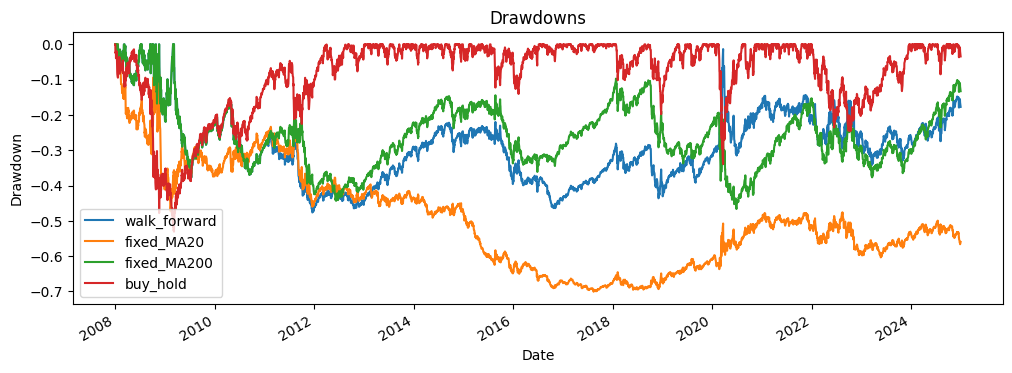

In [59]:
dd = equity / equity.cummax() - 1
dd.plot(figsize=(12, 4), title='Drawdowns')
plt.ylabel('Drawdown')
plt.show()

In [60]:
def position(close, window):
    ma  = close.rolling(window).mean()
    sig = pd.Series(np.where(close > ma, 1.0, -1.0), index=close.index)
    sig[ma.isna()] = np.nan
    return sig.shift(1)

oos_pos  = pd.concat([position(close, f.best_window).loc[f.test_start:f.test_end]
                      for _, f in folds.iterrows()])
turnover = oos_pos.diff().abs().fillna(0)            # 2 per flip, includes switches between folds
print('Flips per year:', round((turnover > 0).sum() / (len(turnover) / 252), 1))

for bp in [0, 2, 5, 10]:
    net = np.log1p(np.expm1(oos_ret) - bp / 1e4 * turnover)
    print(f'{bp:>2} bp/side  ->  Sharpe {sharpe(net):.2f},  CAGR {perf(net)["CAGR"]:.2%}')

Flips per year: 15.4
 0 bp/side  ->  Sharpe 0.21,  CAGR 2.26%
 2 bp/side  ->  Sharpe 0.18,  CAGR 1.63%
 5 bp/side  ->  Sharpe 0.13,  CAGR 0.69%
10 bp/side  ->  Sharpe 0.06,  CAGR -0.85%


In [ ]:
# Performance analysis
'''
a) OutOfSample on its own
b) With the benchmark
c) With the IS and OOS performance


1) OOS performance metrics: Years, Equity curve, CAGR, Vol, SR, DD, MAX_DD, t-stat
    for strategy, benchmark, fixed window

2) Walk forward efficiency(WFE)
    IS vs OOS: Sharpe oos vs mean(IS sharpe)
    Correlation between IS Sharpe and OOS Sharpe

3) Does optimizing beats not optimizing?
    Sharpe: Optimizing vs fixed windows over the stitched period of test.

4) Parameter stability
    How stable is the chosen window over the time period.
    Frequent switches from one window to other is bad.

5) Consistency across folds
    How many good period does the result depend on?
    Remove top performing folds and does the sharpe collapse/ or it starts loosing to buy hold/benchmark.
    Remove the best two folds mentally. If the strategy then loses to buy-and-hold everywhere else, it is a crash hedge, not a general edge. That can still be useful, but it is a different claim.

6) Drawdowns
    If walk-forward has a CAGR similar to buy-and-hold but a much smaller MaxDD, that is a real result.

7) Realistic scenario
   Transaction Cost Sensitivity
    So far every trade has been free. To add costs, rebuild the positions
    If the Sharpe collapses at 2–5 bp, the strategy trades too often for its edge. For S&P futures or ETFs, a few basis points per side is realistic.



OVERALL INTERPRETATION

How to interpret the overall picture

We see	                                                                                    It means
OOS Sharpe well below IS, WFE near 0, rank correlation near 0	                              The optimization fits noise. The window choice has no out-of-sample value.
Walk-forward below the median fixed window	                                                Re-optimizing actively hurts. Use a fixed, pre-committed rule instead.
Walk-forward ≈ fixed windows, all with modest Sharpe	                                      Trend-following has some edge, but the window doesn’t matter much.
Lower CAGR than buy-and-hold, much smaller MaxDD	                                          It works as risk management or a crash hedge, not as alpha.
Gains concentrated in 1–2 folds	                                                            Fragile result that depends on a couple of episodes.
Edge disappears at 5 bp	                                                                    Not tradable as is.

'''